# DIFFUSION EQUATION WITH PSEUDOPSECTRAL METHOD OF LINES AND MONTE-CARLO

In [1]:
from matplotlib import pyplot as plt
import numpy as np
import scipy

## PDE METHOD

$$ P_t = \alpha P_{xx} , \quad 0 \leq t \leq 1, \quad -1 \leq x \leq 1$$

$$ P(0,x) = \frac{1}{\sqrt{2 \pi \sigma_0^2}} e^\frac{-x^2}{2 \sigma_0^2}$$

$$ P(t,x) =  \frac{1}{\sqrt{2 \pi (\sigma_0^2 + 2\alpha t)}} e^\frac{-x^2}{2 (\sigma_0^2 + 2\alpha t)} $$

The above is used to find boundary conditions at any time.

$$ P(t,-1) = P(t,1) = \frac{1}{\sqrt{2 \pi (\sigma_0^2 + 2\alpha t)}} e^\frac{-1}{2 (\sigma_0^2 + 2\alpha t)} = f(t) $$

Solve with the spectral ansatz

$$ P(t,x) = c_i(t) T^i(x) $$

Substiuting into BC gives us

$$ c_i(t)T^i(-1) = f(t) $$

$$ c_i(t) T^i(+1) = f(t) $$

## Spectral Helpers

In [2]:
n = 50

diff = np.loadtxt('diffmatrix100.txt')[0:n,0:n]

chebyshevs = []
for i in range(0, n):
    chebyshevs.append(scipy.special.chebyt(i))

In [3]:
def calc_T_matrix(dim, xcol):
    T = np.zeros(dim)
    for i in range(0,dim):
        T[i] = chebyshevs[i](xcol)
    return T

#Gauss-Lobatto Nodes

xouterleftcol = np.cos(np.pi*np.linspace(1,n-1, int(n-2/1 + 1))/(n- 1))
xinnercol = np.cos(np.pi*np.linspace(1, n-2, int(n-3/1 + 1))/(n-1))
xouterrightcol = np.cos(np.pi*np.linspace(0, n-2, int(n-2/1 + 1))/(n-1))

#the full collocation array
xcol = np.cos(np.pi*np.linspace(0,n-1,n)/(n- 1))

def calc_T():
    Tcol = np.zeros((len(xcol),n))
    Touterleftcol = np.zeros((len(xouterleftcol),n))
    Tinnercol = np.zeros((len(xinnercol),n))
    Touterrightcol = np.zeros((len(xouterrightcol),n))
    for i in range(0, len(xcol)):
        Tcol[i,:] =calc_T_matrix(n, xcol[i])
    for i in range(0, len(xouterleftcol)):
        Touterleftcol[i,:] = calc_T_matrix(n, xouterleftcol[i])
    for i in range(0, len(xinnercol)):
        Tinnercol[i,:] = calc_T_matrix(n, xinnercol[i])
    for i in range(0, len(xouterrightcol)):
        Touterrightcol[i,:] = calc_T_matrix(n, xouterrightcol[i])
    return Tcol, Touterleftcol, Tinnercol, Touterrightcol

Tcol, Touterleftcol, Tinnercol, Touterrightcol = calc_T()
Tdiffouterleftcol = np.matmul(Touterleftcol, diff)
Tdiff2outerleftcol = np.matmul(np.matmul(Touterleftcol, diff), diff)
Tdiffinnercol = np.matmul(Tinnercol, diff)
Tdiff2innercol = np.matmul(np.matmul(Tinnercol, diff), diff)
Tdiffouterrightcol = np.matmul(Touterrightcol, diff)
Tdiff2outerrightcol = np.matmul(np.matmul(Touterrightcol, diff), diff)

TL = calc_T_matrix(n, -1.)
TR = calc_T_matrix(n, +1.)

## Match to Initial Condition

In [4]:
def get_coeff(f):

    c = np.linalg.solve(Tcol, f(0.,xcol))
    return c

In [5]:
#random walk params

sigma = np.sqrt(1e-3) #step length from N(0, sigma^2)
tau = 1e-3 #time interval between steps/step length
alpha = sigma**2./(2*tau)



In [6]:
sigma0 = 1e-1

f_ana = lambda t,x: (1/np.sqrt(2*np.pi*(sigma0**2 + 2*alpha*t)))*np.exp(-x**2./(2*(sigma0**2 + 2*alpha*t)))

c_ID = get_coeff(f_ana)

In [7]:
# functions to plot data

xplot = np.linspace(-1,1,101)

def calc_u(c,x):
    sum = 0.0
    for i in range(len(c)):
        sum = sum + c[i]*chebyshevs[i](x)
    return sum

def plot_frame(c,t):

  
    plt.plot(xplot, calc_u(c, xplot), c='blue')
    plt.plot(xplot, f_ana(t,xplot), c='red', linestyle='dashed')
       
    plt.title('Solution at t: '+str(t))
    plt.ylabel(r'$P$')
    plt.xlabel(r'$x$')
    plt.show()
    

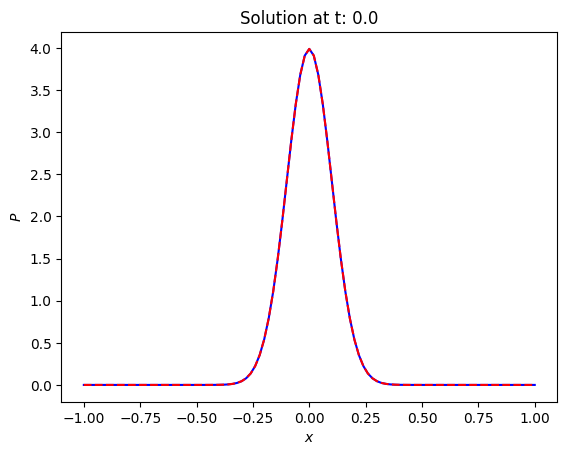

In [8]:
plot_frame(c_ID, 0.)

## Time Evolution

In [9]:
# t array

t = np.linspace(0, 1, int(1/10**-3 + 1))
dt = t[1:] - t[0:-1]

# solution array

c = np.zeros((len(t), n))

c[0,:] = c_ID

The Crank-Nicholson scheme adapted to the pseudospectral method of lines technique:

$$ \frac{u^{1} - u^{0}}{dt} = \alpha \frac{1}{2}(u^{0}_{xx} + u^{1}_{xx})$$

$$ c^1T - c^0T = \alpha \frac{dt}{2} c^0 D^2T + \alpha \frac{dt}{2} c^1 D^2 T$$

$$ (T - \alpha \frac{dt}{2} D^2 T) c^1 = (T + \alpha \frac{dt}{2} D^2 T) c^0$$

In [10]:
def solve_heat_time_slice(c, t, dt):

    L = np.zeros((n,n))
    R = np.zeros((n,n))

    ################################################################################

    #prepare the matrices

    L[0:n-2,:] = Tinnercol - alpha*(dt/2)*Tdiff2innercol

    R[0:n-2,:] = Tinnercol + alpha*(dt/2)*Tdiff2innercol

    R = R@c


    ##################################################################################

    #boundary conditions

    L[-2,:] = TL
    R[-2] = f_ana(t + dt, -1. )
    L[-1,:] = TR
    R[-1] = f_ana(t + dt, +1.)


    return np.linalg.solve(L,R)

In [11]:
for i in range(0, len(t)-1):
    c[i+1,:] = solve_heat_time_slice(c[i,:], t[i], dt[i])

## Visualize Solution

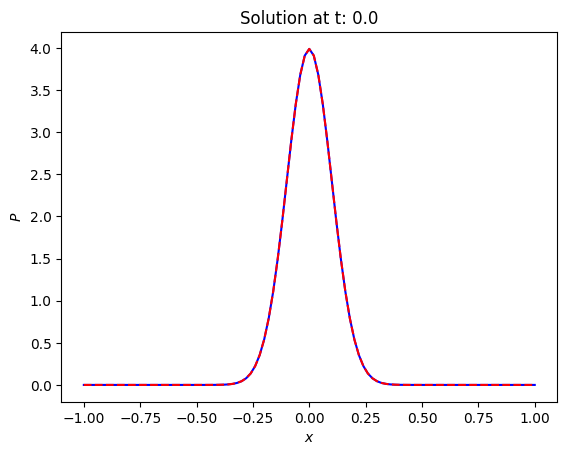

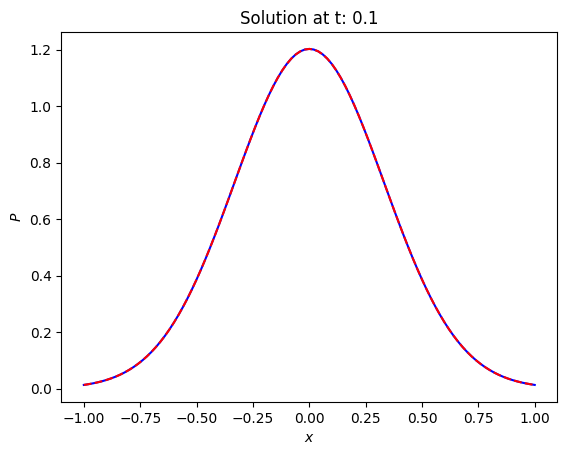

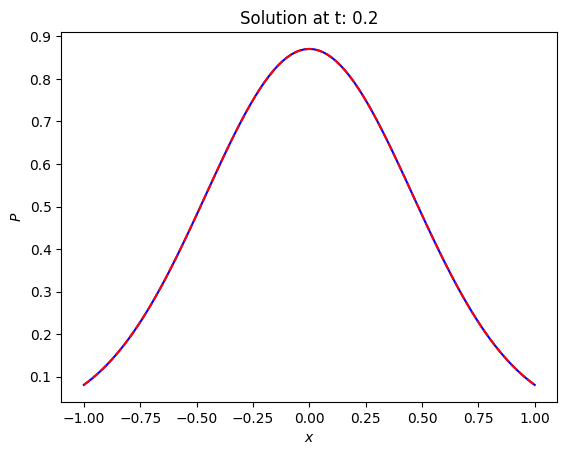

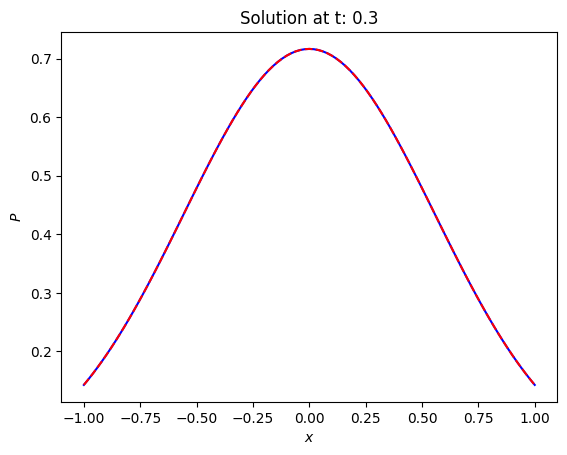

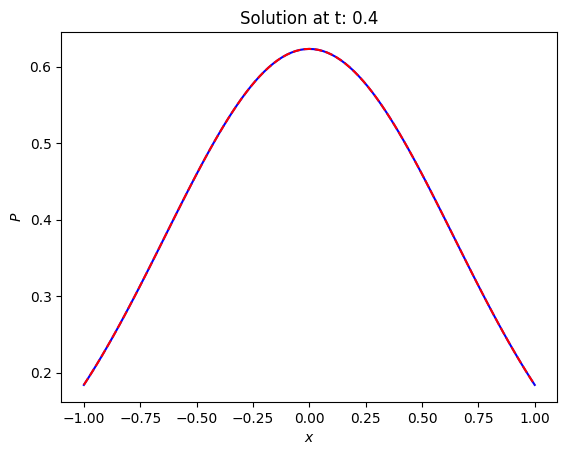

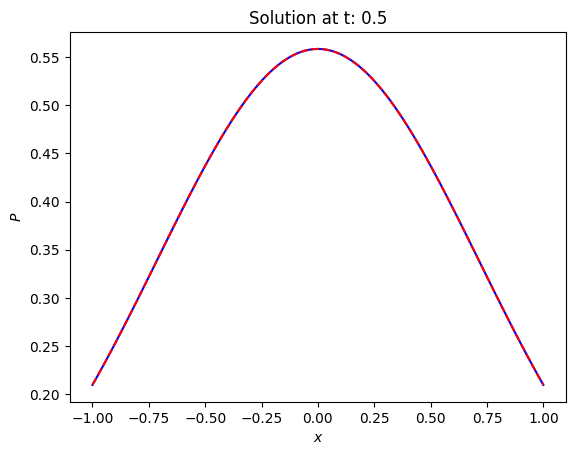

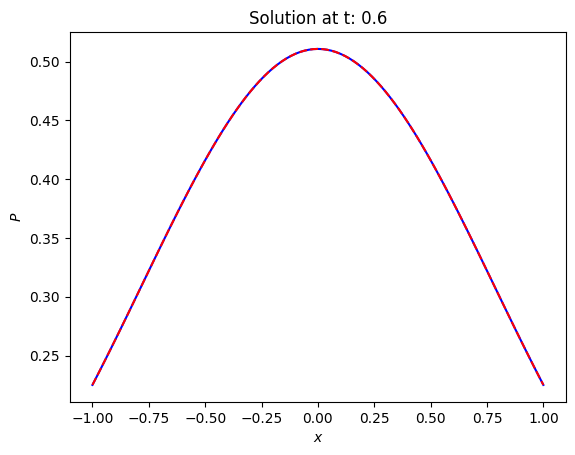

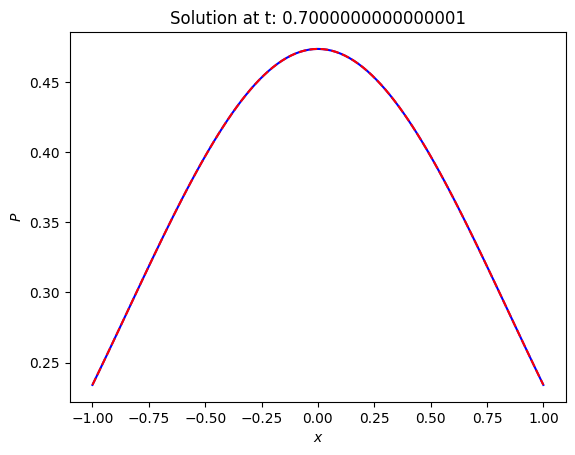

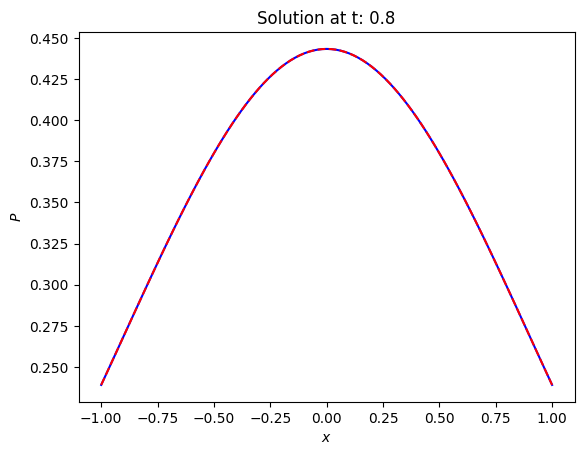

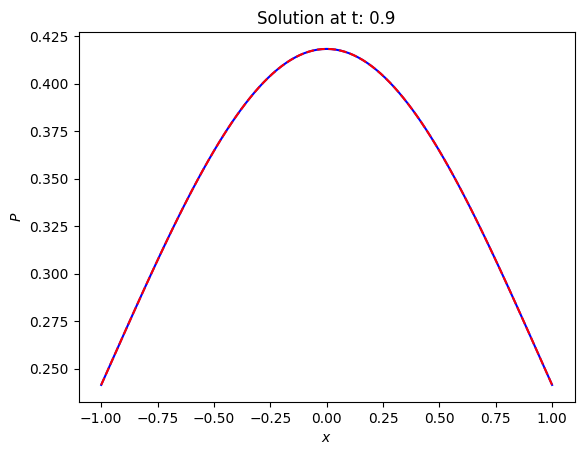

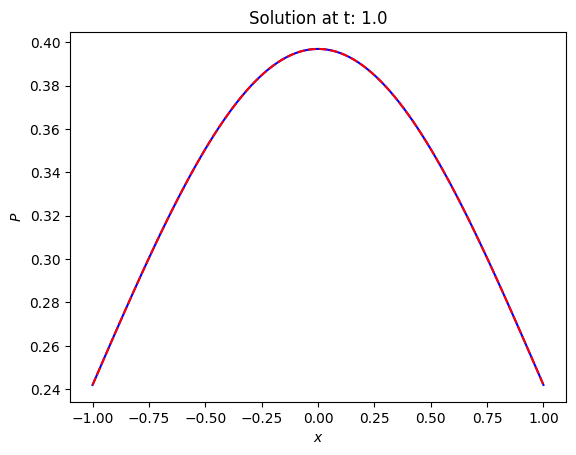

In [12]:
for i in range(0, len(t)):
    if i%100 == 0:
        plot_frame(c[i,:], t[i])
    

## MONTE-CARLO RANDOM WALK METHOD

The same probability distribution is true for $N$ walkers that take steps in intervals of length $\tau$ drawn from a normal distribution $N(0, \sigma^2)$ such that the diffusion coefficient is $\alpha = \frac{\sigma^2}{2 \tau}$.

In [13]:
N = 1000 #number of walkers

In [14]:
def monte_carlo_diffusion(N): 
    walker_data = np.zeros((len(t), N))

    #initialize walker positions
    walker_data[0,:] = np.random.normal(0.0, sigma0, size = N)   # shape (N,), one position per walker

    #perform random walks   
    for i in range(0, len(t)-1):
        walker_data[i+1,:] = walker_data[i,:] + np.random.normal(0.0, sigma, size = N)   # each walker gets its own independent increment

    return walker_data


In [15]:
walker_data = monte_carlo_diffusion(N)

In [16]:
#Extract Diffusion Coefficient
walker_variance = np.var(walker_data, axis=1)   # shape (t,)


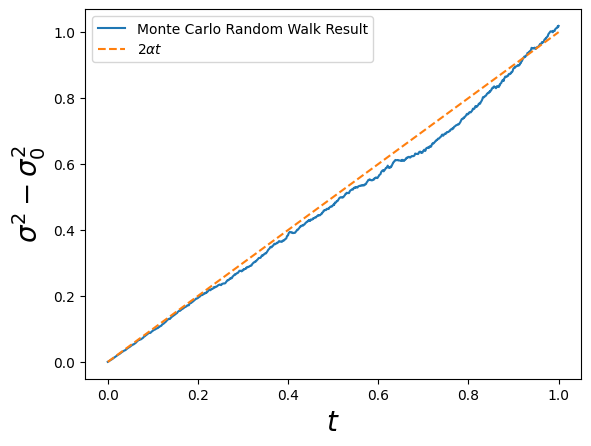

In [17]:
plt.plot(t, walker_variance - sigma0**2., label ='Monte Carlo Random Walk Result')
plt.plot(t, 2*alpha*t, linestyle='dashed', label =r'$2 \alpha t$')
plt.legend()
plt.xlabel(r'$t$', fontsize = 20)
plt.ylabel(r'$\sigma^2 - \sigma_0^2$', fontsize = 20)
plt.show()

## VISUALIZE ALL THE DATA TOGETHER

In [20]:
def plot_frame(index, ax):
    
    bins = np.linspace(-5*np.sqrt(sigma0**2 + 1), 5*np.sqrt(sigma0**2 + 1), 80)   # s_max = sqrt(s0**2 + 2*D*t_max)
    ax.hist(walker_data[index, :], bins=bins, density=True, label='Monte Carlo')
    ax.plot(xplot, calc_u(c[index,:], xplot), c='green', label ='Numerical PDE')
    ax.plot(np.linspace( -5*np.sqrt(sigma0**2 + 1), 5*np.sqrt(sigma0**2 + 1),1000), f_ana(t[index],np.linspace( -5*np.sqrt(sigma0**2 + 1), 5*np.sqrt(sigma0**2 + 1),1000)), c='orange', linestyle='dashed', label ='Analytical Solution')
    

    ax.annotate(f'Time: {t[index]:.2f} s', (-1.45, 3.45), c='black', fontsize = 20)

    ax.set_xlim([-1.5,1.5])
    ax.set_ylim([-0.1,4.1])
    ax.set_xlabel(r'$x$', fontsize = 20)
    ax.set_ylabel(r'$P(t,x)$', fontsize = 20)
    ax.set_title(r'$P_t = \alpha P_{xx} $', fontsize =30)
    #ax.set_xticks([])
    #ax.set_yticks([])
    ax.legend()
    
    
    

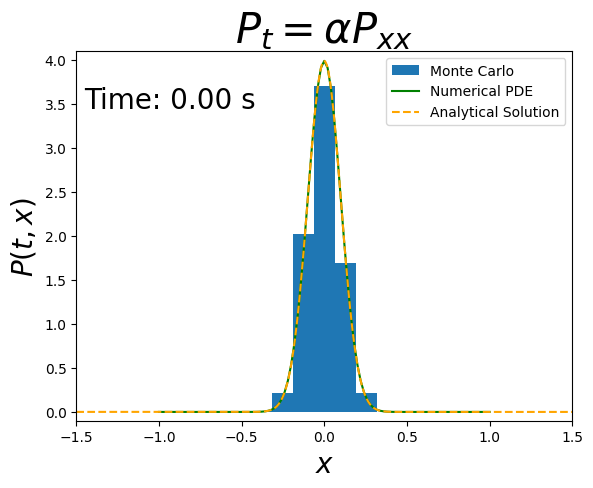

In [21]:
fig, ax = plt.subplots()
#fig.patch.set_facecolor('black')
#ax.set_facecolor('black')
plot_frame(0,ax)
plt.show()

In [22]:
from matplotlib.animation import PillowWriter

In [23]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

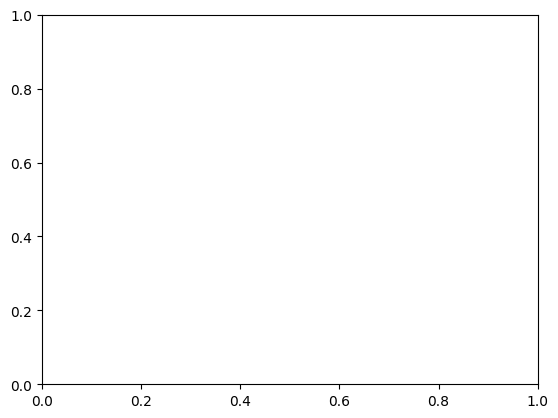

In [24]:
fig, ax = plt.subplots()

with writer.saving(fig, 'diffusion.gif',100):
    for i in range(0, len(t)):
        if i%4 == 0:
            plot_frame(i, ax)
            writer.grab_frame()
            ax.clear()